### 1. Données  

Traitement et de la couche géospatiale epci_with_demo_metropole2154_.gpkg (reprojection en Lambert-93 EPSG:2154 pour calculer la surface des polygones en km2 et la proportion d’étrangers en %, puis passage en EPSG:4326 pour la cartographie web).


Avec Folium, je crée d’abord une carte centrée sur la France avec un fond choisi, j’ajoute une couche choroplèthe qui relie chaque polygone (id_epci) à sa valeur (proportion_etrangers) pour le colorer avec la palette YlOrRd, puis j’enregistre la carte interactive en HTML sur mon ordi.


In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as colors  # Nécessaire pour l'échelle log
import pandas as pd
import folium

chemin_gpkg = "epci_with_demo_metropole2154_.gpkg"
gdf = gpd.read_file(chemin_gpkg)

gdf = gdf.to_crs(epsg=2154)
print(f"Système de coordonnées actuel : {gdf.crs}")

print(gdf.columns)
print(gdf.head(15))



gdf["proportion_etrangers"] = (gdf.etrangers / gdf.Tous)*100 # %%

gdf["polygone_surface"] = gdf.geometry.area / 1e6   #pour mettre en km2

print('%%%%')
print(gdf[["polygone_surface"]].head(10))
print('%%%%')
# 2. Passage en WGS84 (EPSG:4326) pour Folium et ajout d'un identifiant unique
gdf_4326 = gdf.dropna(subset=["proportion_etrangers"]).to_crs(epsg=4326).copy()
gdf_4326["id_epci"] = gdf_4326.index.astype(str)

# m = folium.Map(location=[46.6, 2.5], zoom_start=6)
m = folium.Map(location=[46.6, 2.5], zoom_start=6)

folium.Choropleth(
    geo_data=gdf_4326.to_json(),
    data=gdf_4326,
    columns=["id_epci", "proportion_etrangers"],
    key_on="feature.properties.id_epci",
    fill_color="YlOrRd",
    fill_opacity=0.75,
    line_opacity=0.4,
    legend_name="Proportion étrangers (%)",
).add_to(m)

m.save("carte_proportion_folium_Etrangers.html")

Système de coordonnées actuel : EPSG:2154
Index(['CODE_SIREN', 'NOM', 'NATURE', 'NOM_M', 'NOM_2', 'INSEE_REG', 'Tous',
       'etrangers', 'francaisParAcquisition', 'immigres', 'geometry'],
      dtype='str')
   CODE_SIREN                                    NOM  \
0   200041572                     CC Dronne et Belle   
1   200090751         CA Grand Calais Terres et Mers   
2   200068914  CC La Rochefoucauld porte du Périgord   
3   200026573              CC Haut-Jura Saint-Claude   
4   200066793                     CA du Grand Annecy   
5   200067767                   CC du Royans-Vercors   
6   200067759        CC Vallées et Plateau d'Ardenne   
7   200041150    CC Terrassonnais Haut Périgord Noir   
8   200067825                 CA Gap-Tallard-Durance   
9   200067791                  CA Pays Foix-Varilhes   
10  200040475                      CC LBN Communauté   
11  200034882                  CC Pays du Mont-Blanc   
12  200067882                 CC Bazois Loire Morvan   
13  200

###  2. Données 

Traitement du fichier data_epci_selection.csv (54 950 lignes, 314 EPCI sur les régions 75 et 76, séparateur ;), pour faire le plot d'un histogramme avec :
- en x les métiers 
- en y le nombre de personnes l'exercant
- les nationalités en couleur directement sur l'histogramme .

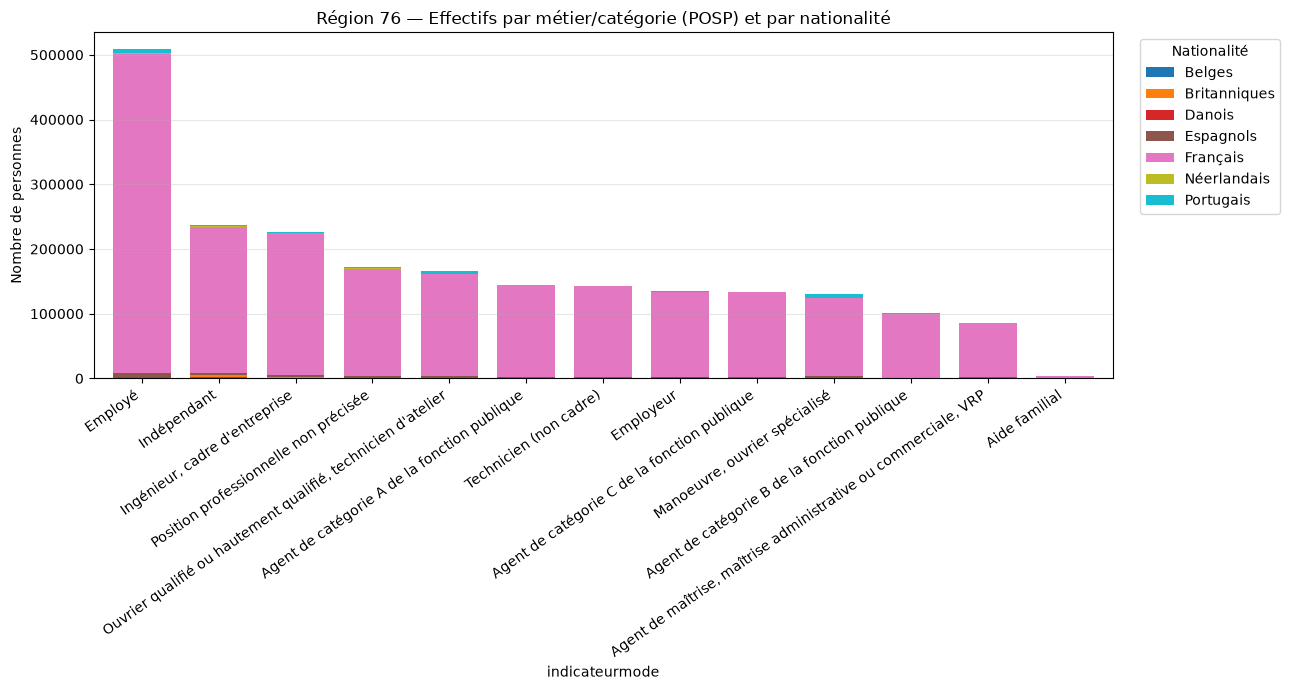

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("data_epci_selection.csv", sep=";")

df_76_posp = df[(df["INSEE_REG"] == 76) & (df["indicateurcode"] == "POSP")].copy()

piv = df_76_posp.pivot_table(
    index="indicateurmode",
    columns="nat",
    values="ensemble",
    aggfunc="sum",
    fill_value=0,
)

piv["Total"] = piv.sum(axis=1)
piv = piv.sort_values("Total", ascending=False).drop(columns=["Total"])
piv = piv.drop(index=["Sans objet"], errors="ignore")  # <-- supprime la catégorie 'Sans objet'

ax = piv.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7),
    colormap="tab10",
    width=0.75,
)

ax.set_title("Région 76 — Effectifs par métier/catégorie (POSP) et par nationalité")
ax.set_ylabel("Nombre de personnes")
ax.legend(title="Nationalité", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("histogramme_reg76_metiers_nationalites.png", dpi=200, bbox_inches="tight")
plt.show()

Ici nous voyons que l'histogramme est écrasé par le nombre de francais dans notre étude, il faut donc utiliser d'autre moyen, ici j'ai choisi de plot toutes les nationalités sauf la francaise pour savoir son importance dans le jeu de données.

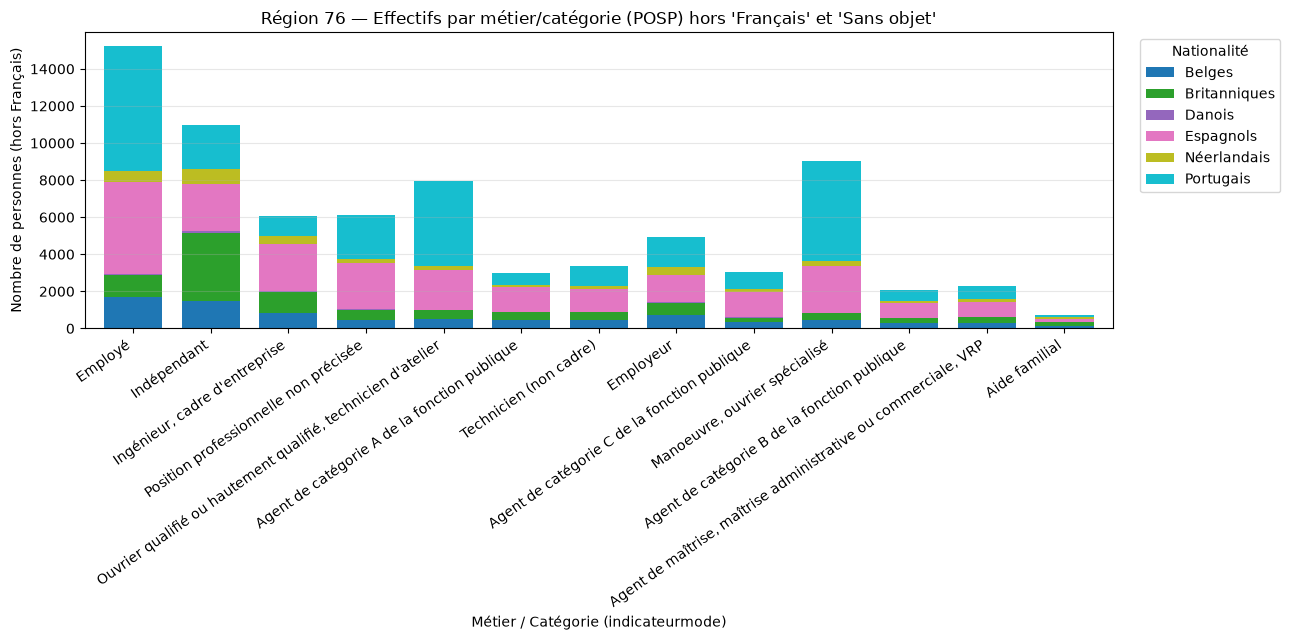

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("data_epci_selection.csv", sep=";")
df_76_posp = df[
    (df["INSEE_REG"] == 76) & (df["indicateurcode"] == "POSP")
].copy()

piv = df_76_posp.pivot_table(
    index="indicateurmode",
    columns="nat",
    values="ensemble",
    aggfunc="sum",
    fill_value=0,
)

order = piv.sum(axis=1).sort_values(ascending=False).index
piv = piv.loc[order]

piv_sans_fr = piv.drop(index=["Sans objet"], errors="ignore").drop(columns=["Français"], errors="ignore")

fig, ax = plt.subplots(figsize=(13, 6.5))
piv_sans_fr.plot(kind="bar", stacked=True, ax=ax, colormap="tab10", width=0.75)
ax.set_title(
    "Région 76 — Effectifs par métier/catégorie (POSP) hors 'Français' et"
    " 'Sans objet'"
)
ax.set_xlabel("Métier / Catégorie (indicateurmode)")
ax.set_ylabel("Nombre de personnes (hors Français)")
ax.legend(title="Nationalité", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("graph_sans_francais_reg76.png", dpi=200, bbox_inches="tight")
plt.show()

Ici je supprime les nationalités Francais, Espagnols, Portugais, pour regarder la distribution des "petites nationalités".

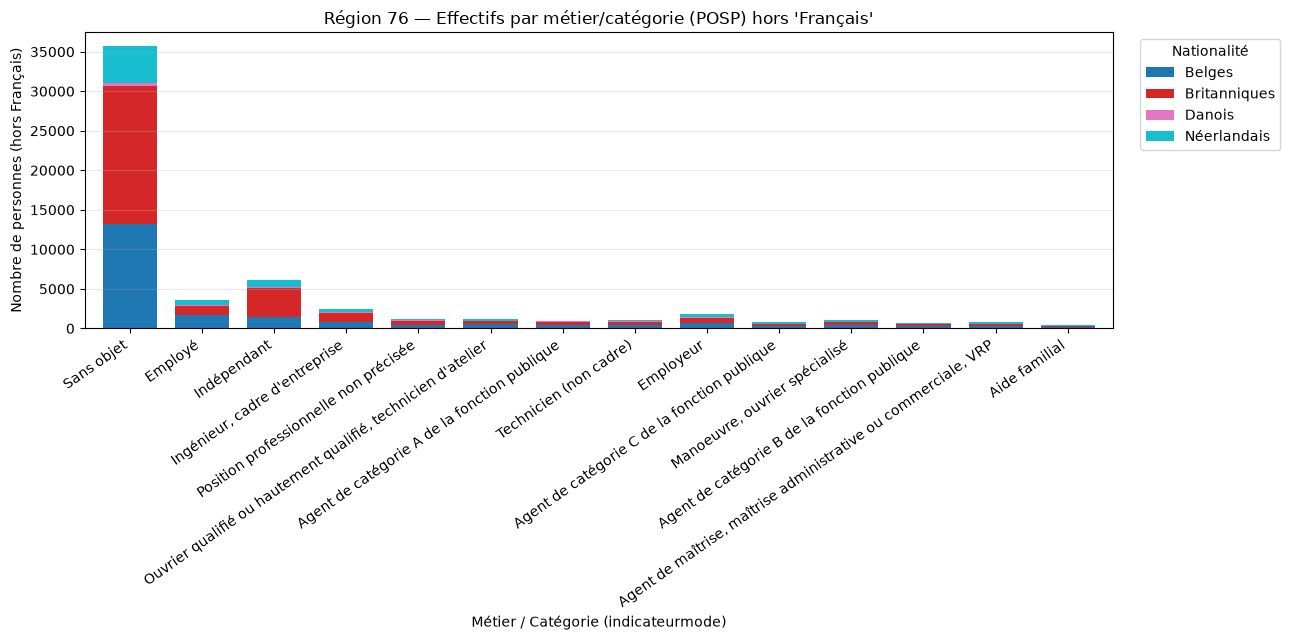

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd


df = pd.read_csv("data_epci_selection.csv", sep=";")
df_76_posp = df[
    (df["INSEE_REG"] == 76) & (df["indicateurcode"] == "POSP")
].copy()

piv = df_76_posp.pivot_table(
    index="indicateurmode",
    columns="nat",
    values="ensemble",
    aggfunc="sum",
    fill_value=0,
)

order = piv.sum(axis=1).sort_values(ascending=False).index
piv = piv.loc[order]

piv_sans_fr = piv.drop(index=["Sans objet"], errors="ignore").drop(columns=["Français",  "Espagnols", "Portugais"], errors="ignore")

fig, ax = plt.subplots(figsize=(13, 6.5))
piv_sans_fr.plot(kind="bar", stacked=True, ax=ax, colormap="tab10", width=0.75)
ax.set_title(
    "Région 76 — Effectifs par métier/catégorie (POSP) hors 'Français'"
)
ax.set_xlabel("Métier / Catégorie (indicateurmode)")
ax.set_ylabel("Nombre de personnes (hors Français)")
ax.legend(title="Nationalité", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("graph_sans_francais_reg76.png", dpi=200, bbox_inches="tight")
plt.show()

In [16]:
%matplotlib inline

Shape piv_filtre : (13, 6)
nat                                                 Belges  Britanniques  \
indicateurmode                                                             
Employé                                               1670          1223   
Indépendant                                           1498          3627   
Ingénieur, cadre d'entreprise                          835          1147   
Position professionnelle non précisée                  475           512   
Ouvrier qualifié ou hautement qualifié, technic...     507           463   

nat                                                 Danois  Espagnols  \
indicateurmode                                                          
Employé                                                 60       4965   
Indépendant                                            116       2530   
Ingénieur, cadre d'entreprise                           48       2541   
Position professionnelle non précisée                   40       2518   
Ou

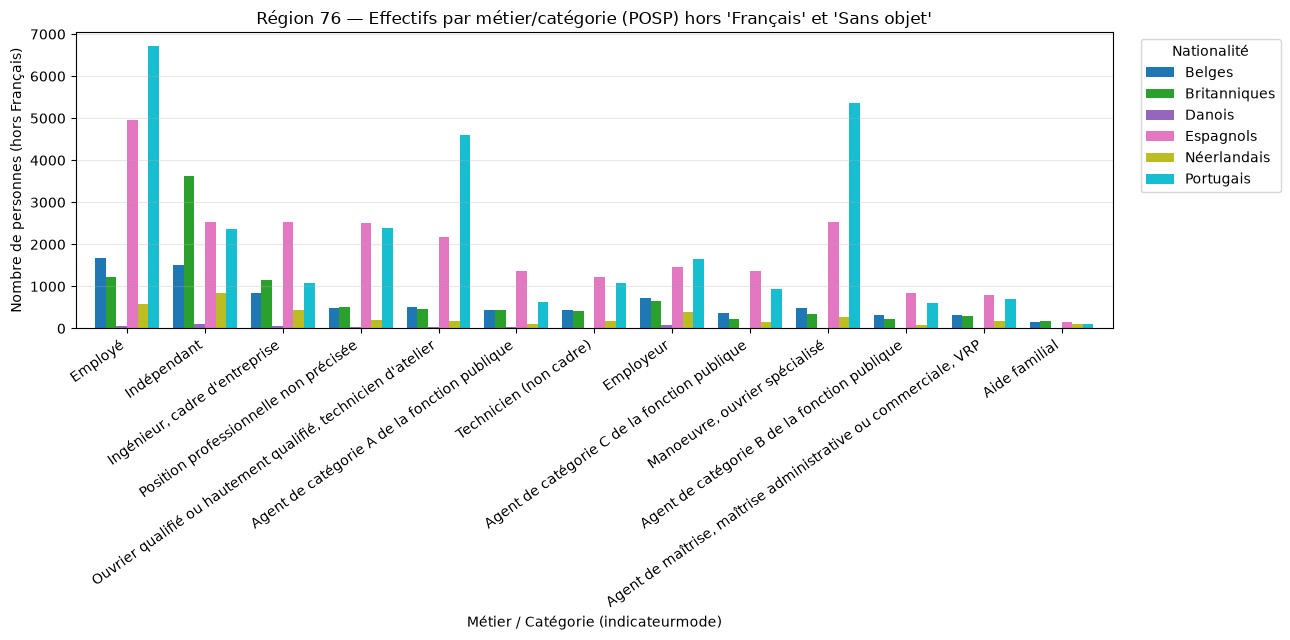

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("data_epci_selection.csv", sep=";")
df_76_posp = df[
    (df["INSEE_REG"] == 76) & (df["indicateurcode"] == "POSP")
].copy()

piv = df_76_posp.pivot_table(
    index="indicateurmode",
    columns="nat",
    values="ensemble",
    aggfunc="sum",
    fill_value=0,
)

order = piv.sum(axis=1).sort_values(ascending=False).index
piv = piv.loc[order]

piv_filtre = piv.drop(index=["Sans objet"], errors="ignore").drop(
    columns=["Français"], errors="ignore"
)

print("Shape piv_filtre :", piv_filtre.shape)
print(piv_filtre.head())

if piv_filtre.empty:
  print("Attention : piv_filtre est vide !")
else:
  fig, ax = plt.subplots(figsize=(13, 6.5))
  piv_filtre.plot(
      kind="bar", stacked=False, ax=ax, colormap="tab10", width=0.82
  )
  ax.set_title(
      "Région 76 — Effectifs par métier/catégorie (POSP) hors 'Français' et"
      " 'Sans objet'"
  )
  ax.set_xlabel("Métier / Catégorie (indicateurmode)")
  ax.set_ylabel("Nombre de personnes (hors Français)")
  ax.legend(title="Nationalité", bbox_to_anchor=(1.02, 1), loc="upper left")
  ax.grid(axis="y", alpha=0.3)
  plt.xticks(rotation=35, ha="right")
  plt.tight_layout()
  plt.show()

In [13]:
import base64
from io import BytesIO
from pathlib import Path
import traceback
from flask import Flask, render_template
import matplotlib
import pandas as pd

matplotlib.use("Agg")
import matplotlib.pyplot as plt

BASE_DIR = Path.cwd()
CSV_PATH = BASE_DIR / "data_epci_selection.csv"
TEMPLATES_DIR = BASE_DIR / "templates"
TEMPLATES_DIR.mkdir(parents=True, exist_ok=True)

# Crée automatiquement templates/graphique.html s'il n'existe pas
TEMPLATE_PATH = TEMPLATES_DIR / "graphique.html"
if not TEMPLATE_PATH.exists():
  TEMPLATE_PATH.write_text(
      """<!doctype html>
<html lang="fr">
<head>
  <meta charset="utf-8">
  <title>Histogramme Région 76</title>
  <style>
    body {
      font-family: Arial, sans-serif;
      margin: 30px;
      background-color: #f7f8fa;
    }
    .container {
      max-width: 1200px;
      margin: auto;
      background: #ffffff;
      padding: 24px;
      border-radius: 8px;
      box-shadow: 0 2px 8px rgba(0, 0, 0, 0.08);
    }
    h1 {
      margin-top: 0;
      font-size: 1.4rem;
    }
    img {
      width: 100%;
      height: auto;
      display: block;
    }
  </style>
</head>
<body>
  <div class="container">
    <h1>Région 76 — Effectifs par métier/catégorie (POSP) hors 'Français' et 'Sans objet'</h1>
    <img src="data:image/png;base64,{{ image_b64 }}" alt="Graphique Région 76 par métier et nationalité">
  </div>
</body>
</html>
""",
      encoding="utf-8",
  )

app = Flask(__name__, template_folder=str(TEMPLATES_DIR))


def generer_histogramme_reg76_base64() -> str:
  df = pd.read_csv(CSV_PATH, sep=";")
  df_76_posp = df[
      (df["INSEE_REG"] == 76) & (df["indicateurcode"] == "POSP")
  ].copy()

  piv = df_76_posp.pivot_table(
      index="indicateurmode",
      columns="nat",
      values="ensemble",
      aggfunc="sum",
      fill_value=0,
  )

  order = piv.sum(axis=1).sort_values(ascending=False).index
  piv = piv.loc[order]

  piv_filtre = piv.drop(index=["Sans objet"], errors="ignore").drop(
      columns=["Français"], errors="ignore"
  )

  fig, ax = plt.subplots(figsize=(13, 6.5))
  piv_filtre.plot(
      kind="bar",
      stacked=False,
      ax=ax,
      colormap="tab10",
      width=0.82,
  )

  ax.set_title(
      "Région 76 — Effectifs par métier/catégorie (POSP) hors 'Français' et"
      " 'Sans objet'"
  )
  ax.set_xlabel("Métier / Catégorie (indicateurmode)")
  ax.set_ylabel("Nombre de personnes (hors Français)")
  ax.legend(title="Nationalité", bbox_to_anchor=(1.02, 1), loc="upper left")
  ax.grid(axis="y", alpha=0.3)

  plt.xticks(rotation=35, ha="right")
  fig.tight_layout()

  buf = BytesIO()
  fig.savefig(buf, format="png", dpi=200, bbox_inches="tight")
  plt.close(fig)
  buf.seek(0)

  return base64.b64encode(buf.getvalue()).decode("utf-8")


@app.route("/")
def index():
  return "Accueil — Allez sur <a href='/graphique'>/graphique</a>"


@app.route("/graphique")
def page_graphique():
  try:
    image_b64 = generer_histogramme_reg76_base64()
    return render_template("graphique.html", image_b64=image_b64)
  except Exception:
    traceback.print_exc()
    return f"<pre>{traceback.format_exc()}</pre>", 500


if __name__ == "__main__":
  app.run(port=5050, debug=False)

 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5050
Press CTRL+C to quit
127.0.0.1 - - [20/Nov/2026 09:09:33] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [20/Nov/2026 09:09:37] "GET /graphique HTTP/1.1" 200 -
